In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [2]:
import zipfile
import os

zip_file = next(iter(uploaded))

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall("/content/brain_mri")

for root, dirs, files in os.walk("/content/brain_mri"):
    if dirs:
        print(root, dirs)

/content/brain_mri ['Testing', 'Training']
/content/brain_mri/Testing ['meningioma', 'glioma', 'notumor', 'pituitary']
/content/brain_mri/Training ['meningioma', 'glioma', 'notumor', 'pituitary']


In [3]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import random

DATA_DIR = "/content/brain_mri"

train_dir = os.path.join(DATA_DIR, "Training")
test_dir = os.path.join(DATA_DIR, "Testing")

classes = ["glioma", "meningioma", "notumor", "pituitary"]

for cls in classes:
    train_count = len(os.listdir(os.path.join(train_dir, cls)))
    test_count = len(os.listdir(os.path.join(test_dir, cls)))
    print(f"{cls}: Training={train_count}, Testing={test_count}")

glioma: Training=1400, Testing=400
meningioma: Training=1400, Testing=400
notumor: Training=1400, Testing=400
pituitary: Training=1400, Testing=400


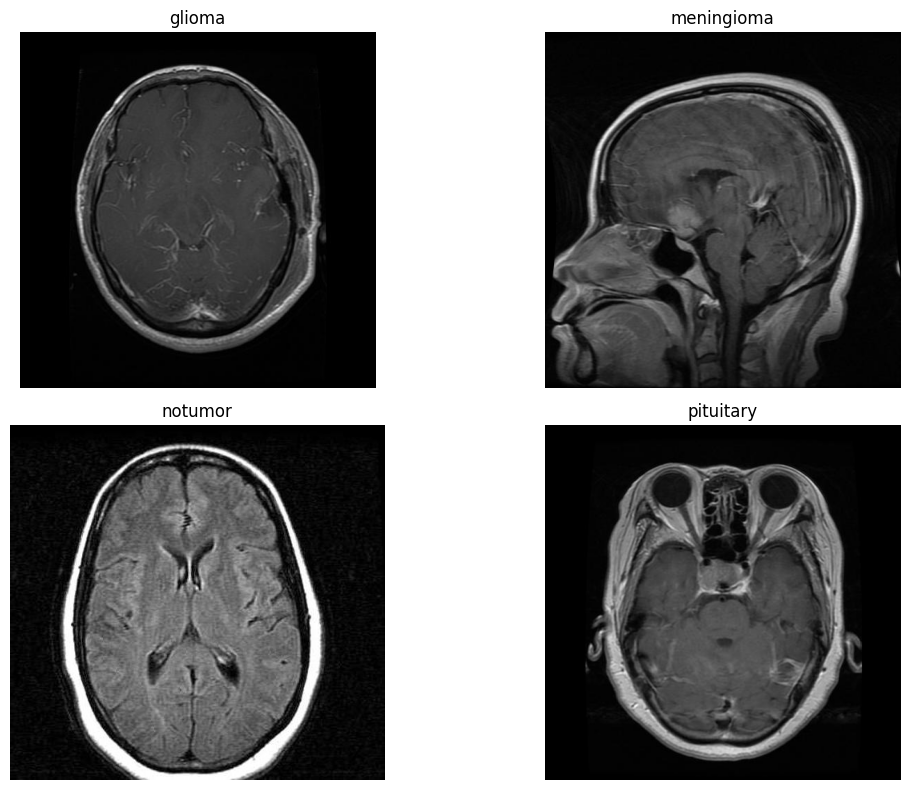

In [4]:
plt.figure(figsize=(12, 8))

for i, cls in enumerate(classes):
    folder = os.path.join(train_dir, cls)
    img_name = random.choice(os.listdir(folder))
    img = Image.open(os.path.join(folder, img_name)).convert("RGB")

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/brain_mri/Training",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/brain_mri/Training",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/brain_mri/Testing",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="int"
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


In [6]:
from tensorflow.keras import layers, Model

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 23s 76ms/step - accuracy: 0.7386 - loss: 0.6695 - val_accuracy: 0.8830 - val_loss: 0.3555
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - accuracy: 0.8529 - loss: 0.4035 - val_accuracy: 0.8991 - val_loss: 0.2750
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.8717 - loss: 0.3438 - val_accuracy: 0.9062 - val_loss: 0.2643
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accuracy: 0.8797 - loss: 0.3106 - val_accuracy: 0.9214 - val_loss: 0.2332
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 8s 59ms/step - accuracy: 0.8969 - loss: 0.2800 - val_accuracy: 0.9241 - val_loss: 0.2220


In [8]:
test_loss, test_acc = model.evaluate(test_ds)

print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.8562 - loss: 0.4882
Test Accuracy: 85.62%
Test Loss: 0.4882


50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step
              precision    recall  f1-score   support

      glioma       0.93      0.70      0.80       400
  meningioma       0.75      0.79      0.77       400
     notumor       0.85      0.98      0.91       400
   pituitary       0.92      0.95      0.94       400

    accuracy                           0.86      1600
   macro avg       0.86      0.86      0.85      1600
weighted avg       0.86      0.86      0.85      1600



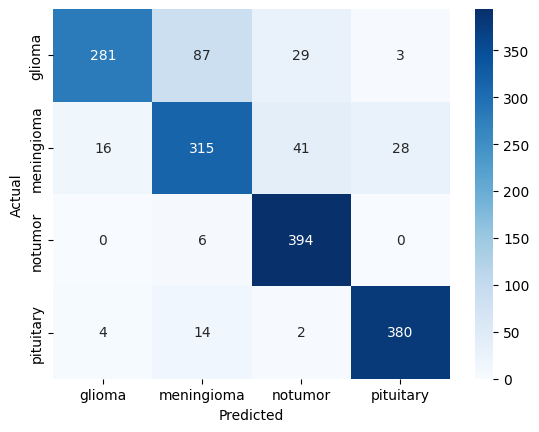

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

sns.heatmap(
    confusion_matrix(y_true, y_pred),
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

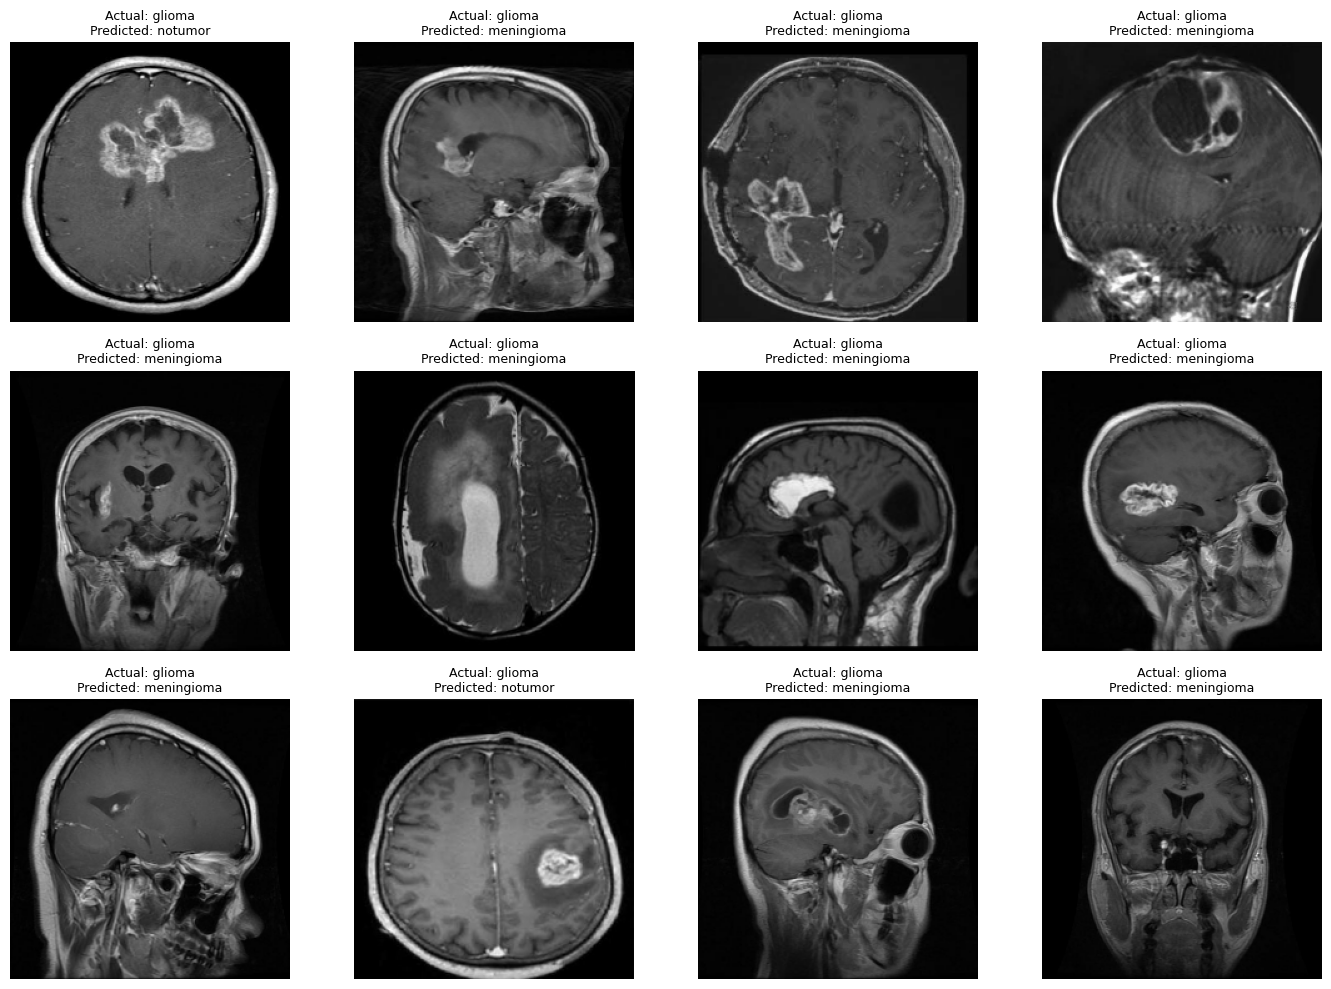

Total misclassified: 230


In [10]:
# Find misclassified test images
wrong_images = []
wrong_actual = []
wrong_predicted = []

for images, labels in test_ds:
    probs = model.predict(images, verbose=0)
    preds = np.argmax(probs, axis=1)

    for i in range(len(labels)):
        if labels[i].numpy() != preds[i]:
            wrong_images.append(images[i].numpy().astype("uint8"))
            wrong_actual.append(class_names[labels[i].numpy()])
            wrong_predicted.append(class_names[preds[i]])

# Display up to 12 mistakes
n = min(12, len(wrong_images))
plt.figure(figsize=(14, 10))

for i in range(n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(wrong_images[i])
    plt.title(
        f"Actual: {wrong_actual[i]}\nPredicted: {wrong_predicted[i]}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Total misclassified:", len(wrong_images))

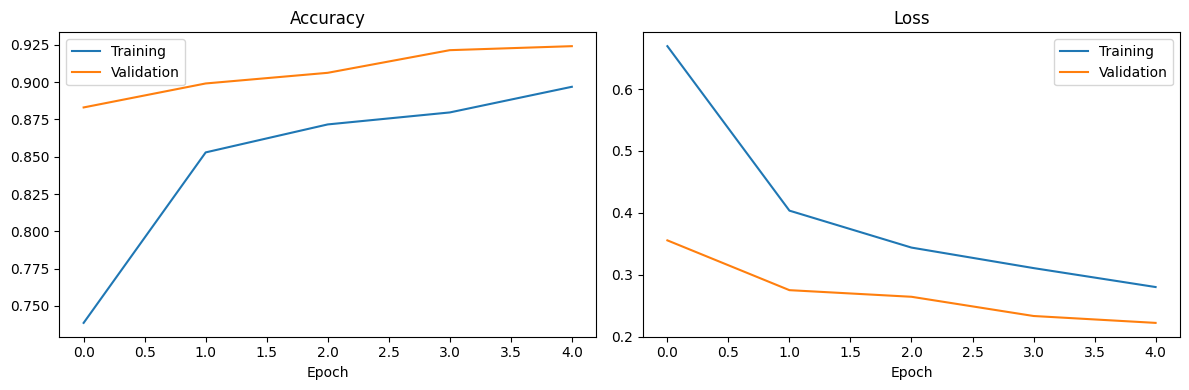

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
model.save("/content/brain_tumour_baseline.keras")

In [13]:
base_model.trainable = True

# Freeze most layers; fine-tune only the last 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3
)

Epoch 1/3
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 84ms/step - accuracy: 0.8301 - loss: 0.4534 - val_accuracy: 0.9241 - val_loss: 0.2183
Epoch 2/3
140/140 ━━━━━━━━━━━━━━━━━━━━ 8s 50ms/step - accuracy: 0.8725 - loss: 0.3194 - val_accuracy: 0.9250 - val_loss: 0.2089
Epoch 3/3
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step - accuracy: 0.9031 - loss: 0.2516 - val_accuracy: 0.9321 - val_loss: 0.1932


In [14]:
test_loss, test_acc = model.evaluate(test_ds, verbose=1)

print(f"Fine-tuned Test Accuracy: {test_acc * 100:.2f}%")
print(f"Fine-tuned Test Loss: {test_loss:.4f}")

50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - accuracy: 0.8550 - loss: 0.6219
Fine-tuned Test Accuracy: 85.50%
Fine-tuned Test Loss: 0.6219


50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step
              precision    recall  f1-score   support

      glioma       0.95      0.70      0.80       400
  meningioma       0.76      0.80      0.78       400
     notumor       0.82      0.98      0.89       400
   pituitary       0.93      0.94      0.94       400

    accuracy                           0.85      1600
   macro avg       0.86      0.85      0.85      1600
weighted avg       0.86      0.85      0.85      1600



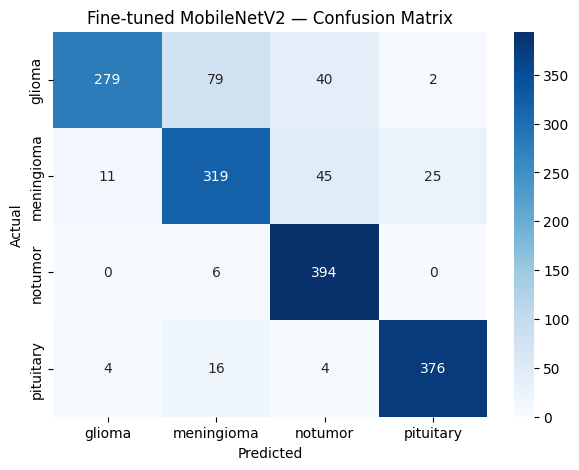

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

plt.figure(figsize=(7, 5))
sns.heatmap(
    confusion_matrix(y_true, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fine-tuned MobileNetV2 — Confusion Matrix")
plt.show()

In [16]:
baseline_model = tf.keras.models.load_model(
    "/content/brain_tumour_baseline.keras"
)

baseline_model.save("/content/brain_tumour_classifier.keras")

In [17]:
import tensorflow as tf
from tensorflow.keras import layers, Model

augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
], name="data_augmentation")

In [18]:
base_aug = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_aug.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_aug(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

aug_model = Model(inputs, outputs)

aug_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

aug_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [19]:
callbacks_aug = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

history_aug = aug_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks_aug
)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step - accuracy: 0.6819 - loss: 0.8093 - val_accuracy: 0.8188 - val_loss: 0.4925
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 74ms/step - accuracy: 0.8040 - loss: 0.5116 - val_accuracy: 0.8375 - val_loss: 0.4380
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.8393 - loss: 0.4209 - val_accuracy: 0.8455 - val_loss: 0.4154
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - accuracy: 0.8522 - loss: 0.3973 - val_accuracy: 0.8393 - val_loss: 0.4360
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step - accuracy: 0.8605 - loss: 0.3698 - val_accuracy: 0.8393 - val_loss: 0.4517


In [20]:
aug_loss, aug_acc = aug_model.evaluate(test_ds, verbose=1)

print(f"Augmented model test accuracy: {aug_acc * 100:.2f}%")
print(f"Augmented model test loss: {aug_loss:.4f}")
print(f"Original baseline: 85.62%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.7731 - loss: 0.6338
Augmented model test accuracy: 77.31%
Augmented model test loss: 0.6338
Original baseline: 85.62%


In [21]:
from PIL import Image
import os
import numpy as np
import pandas as pd

records = []

for split in ["Training", "Testing"]:
    for cls in class_names:
        folder = f"/content/brain_mri/{split}/{cls}"

        image_files = [
            f for f in os.listdir(folder)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            )
        ]

        for filename in image_files[:100]:
            path = os.path.join(folder, filename)

            with Image.open(path) as img:
                arr = np.asarray(img.convert("RGB"))
                records.append({
                    "split": split,
                    "class": cls,
                    "width": img.width,
                    "height": img.height,
                    "mean_intensity": arr.mean(),
                    "std_intensity": arr.std()
                })

df = pd.DataFrame(records)

print(df.groupby(["split", "class"])[
    ["width", "height", "mean_intensity", "std_intensity"]
].mean().round(2))

                      width  height  mean_intensity  std_intensity
split    class                                                    
Testing  glioma      481.08  481.71           39.88          42.61
         meningioma  451.10  460.07           51.13          50.54
         notumor     296.81  301.55           59.42          60.55
         pituitary   509.44  509.44           47.90          41.29
Training glioma      512.00  512.00           33.99          39.03
         meningioma  501.50  501.55           43.29          46.40
         notumor     312.60  318.02           60.99          60.95
         pituitary   530.93  529.21           49.36          40.83


In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

features = [
    "width", "height", "mean_intensity", "std_intensity"
]

train_meta = df[df["split"] == "Training"]
test_meta = df[df["split"] == "Testing"]

metadata_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

metadata_model.fit(
    train_meta[features],
    train_meta["class"]
)

meta_pred = metadata_model.predict(test_meta[features])

print("Metadata-only accuracy:",
      round(accuracy_score(test_meta["class"], meta_pred) * 100, 2), "%")

print(classification_report(
    test_meta["class"],
    meta_pred,
    zero_division=0
))

Metadata-only accuracy: 61.75 %
              precision    recall  f1-score   support

      glioma       0.60      0.53      0.56       100
  meningioma       0.47      0.42      0.44       100
     notumor       0.67      0.85      0.75       100
   pituitary       0.71      0.67      0.69       100

    accuracy                           0.62       400
   macro avg       0.61      0.62      0.61       400
weighted avg       0.61      0.62      0.61       400



In [23]:
from PIL import Image
import os
import numpy as np
import pandas as pd

records = []

for split in ["Training", "Testing"]:
    for cls in class_names:
        folder = f"/content/brain_mri/{split}/{cls}"

        for filename in os.listdir(folder):
            path = os.path.join(folder, filename)

            try:
                with Image.open(path) as img:
                    arr = np.asarray(img.convert("RGB"))

                    records.append({
                        "split": split,
                        "class": cls,
                        "width": img.width,
                        "height": img.height,
                        "mean_intensity": arr.mean(),
                        "std_intensity": arr.std()
                    })
            except Exception:
                continue

full_df = pd.DataFrame(records)

print(full_df.groupby(["split", "class"]).size())

split     class     
Testing   glioma         400
          meningioma     400
          notumor        400
          pituitary      400
Training  glioma        1400
          meningioma    1400
          notumor       1400
          pituitary     1400
dtype: int64


In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

features = [
    "width", "height", "mean_intensity", "std_intensity"
]

train_meta = full_df[full_df["split"] == "Training"]
test_meta = full_df[full_df["split"] == "Testing"]

metadata_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

metadata_model.fit(
    train_meta[features],
    train_meta["class"]
)

pred = metadata_model.predict(test_meta[features])

print("Full metadata-only accuracy:",
      round(accuracy_score(test_meta["class"], pred) * 100, 2), "%")

print(classification_report(
    test_meta["class"],
    pred,
    zero_division=0
))

Full metadata-only accuracy: 63.19 %
              precision    recall  f1-score   support

      glioma       0.62      0.53      0.57       400
  meningioma       0.47      0.42      0.44       400
     notumor       0.69      0.86      0.77       400
   pituitary       0.71      0.72      0.72       400

    accuracy                           0.63      1600
   macro avg       0.62      0.63      0.62      1600
weighted avg       0.62      0.63      0.62      1600



In [25]:
import tensorflow as tf
import copy

extended_model = tf.keras.models.clone_model(baseline_model)
extended_model.set_weights(baseline_model.get_weights())

extended_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [26]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_extended = extended_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 84ms/step - accuracy: 0.9020 - loss: 0.2586 - val_accuracy: 0.9250 - val_loss: 0.2165
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.9096 - loss: 0.2472 - val_accuracy: 0.9241 - val_loss: 0.2133
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.9062 - loss: 0.2505 - val_accuracy: 0.9250 - val_loss: 0.2107
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.9056 - loss: 0.2437 - val_accuracy: 0.9223 - val_loss: 0.2101
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 49ms/step - accuracy: 0.9089 - loss: 0.2408 - val_accuracy: 0.9232 - val_loss: 0.2094
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.9096 - loss: 0.2447 - val_accuracy: 0.9259 - val_loss: 0.2083
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 50ms/step - accuracy: 0.9114 - loss: 0.2402 - val_accuracy: 0.9241 - val_loss: 0.2068
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.9087 - loss: 0.2403 - val_ac

In [27]:
loss, accuracy = extended_model.evaluate(test_ds)

print(f"Extended model test accuracy: {accuracy * 100:.2f}%")
print("Original baseline: 85.62%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.8644 - loss: 0.4675
Extended model test accuracy: 86.44%
Original baseline: 85.62%


50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step
              precision    recall  f1-score   support

      glioma       0.94      0.70      0.80       400
  meningioma       0.75      0.82      0.78       400
     notumor       0.88      0.98      0.93       400
   pituitary       0.92      0.95      0.94       400

    accuracy                           0.86      1600
   macro avg       0.87      0.86      0.86      1600
weighted avg       0.87      0.86      0.86      1600



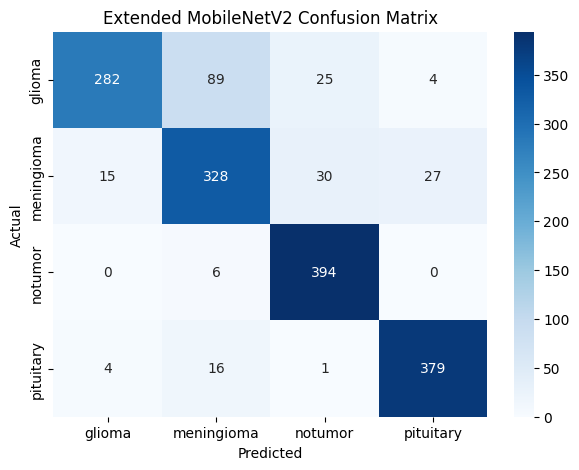

In [28]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred = np.argmax(
    extended_model.predict(test_ds),
    axis=1
)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

plt.figure(figsize=(7, 5))
sns.heatmap(
    confusion_matrix(y_true, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Extended MobileNetV2 Confusion Matrix")
plt.show()

In [29]:
extended_model.save(
    "/content/brain_tumour_classifier_extended.keras"
)

In [31]:
extended_model.save(
    "/content/brain_tumour_classifier_extended.keras"
)

from google.colab import files
files.download(
    "/content/brain_tumour_classifier_extended.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
from google.colab import files

files.download(
    "/content/brain_tumour_classifier_extended.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>